In [1]:
from pathlib import Path

from signal_processing import *

# Load the raw dataset. The loader adds timestamp_ms and time_seconds.
szeli_measurements = data_load("functional_tests/measurements/fdc1004_data_Szeli_K.csv")

(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'Raw capacitance measurements'}, xlabel='Time (seconds)', ylabel='Capacitance'>)

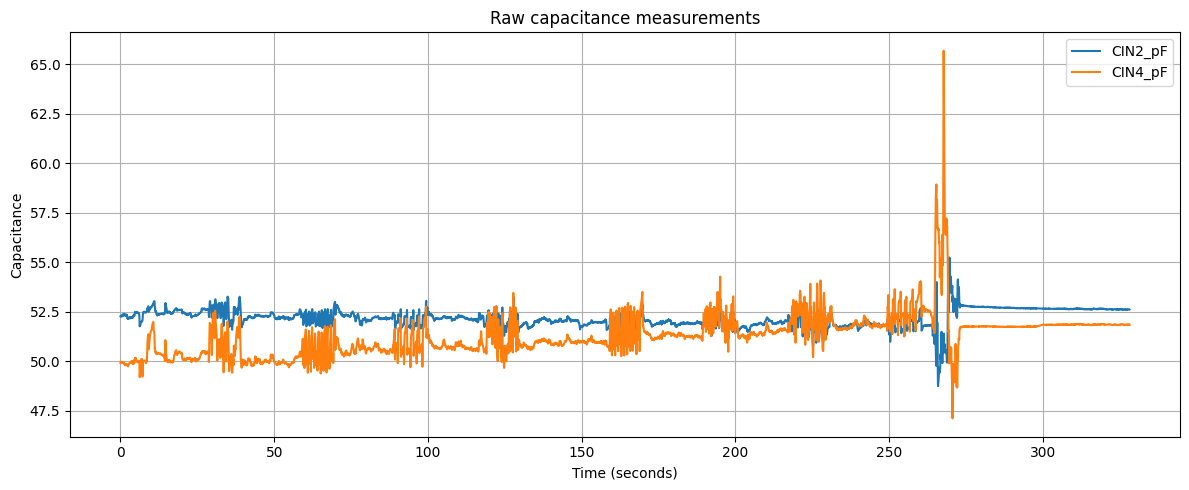

In [2]:
plot(szeli_measurements, channels="both", title="Raw capacitance measurements")

(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'Cut dataset'}, xlabel='Time (seconds)', ylabel='Capacitance'>)

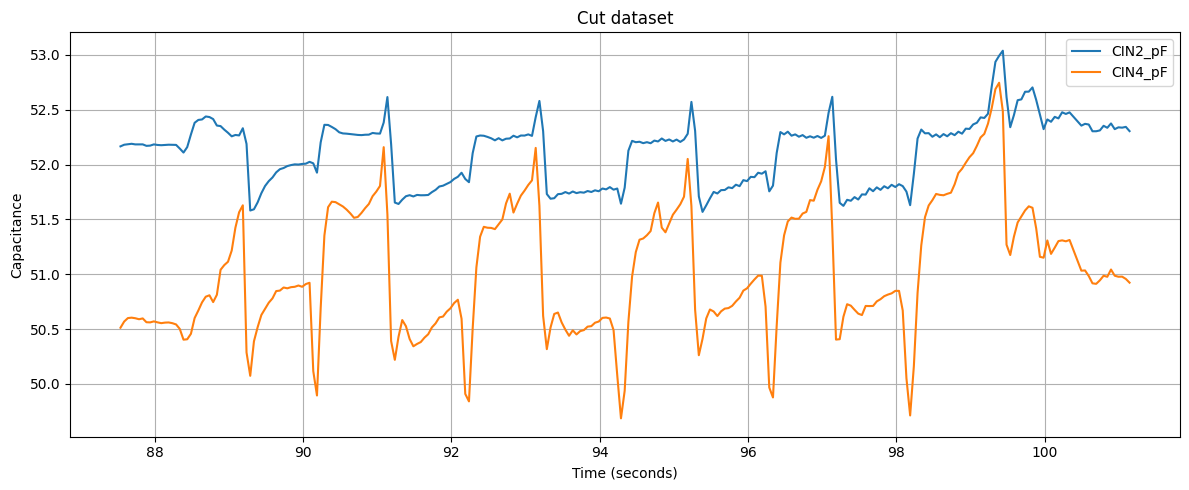

In [3]:
check_movement = cut_dataset(szeli_measurements, start=87.5, end=227)
plot(check_movement, channels="both", title="Cut dataset")

(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'Cut dataset (100-100)'}, xlabel='Time (seconds)', ylabel='Capacitance'>)

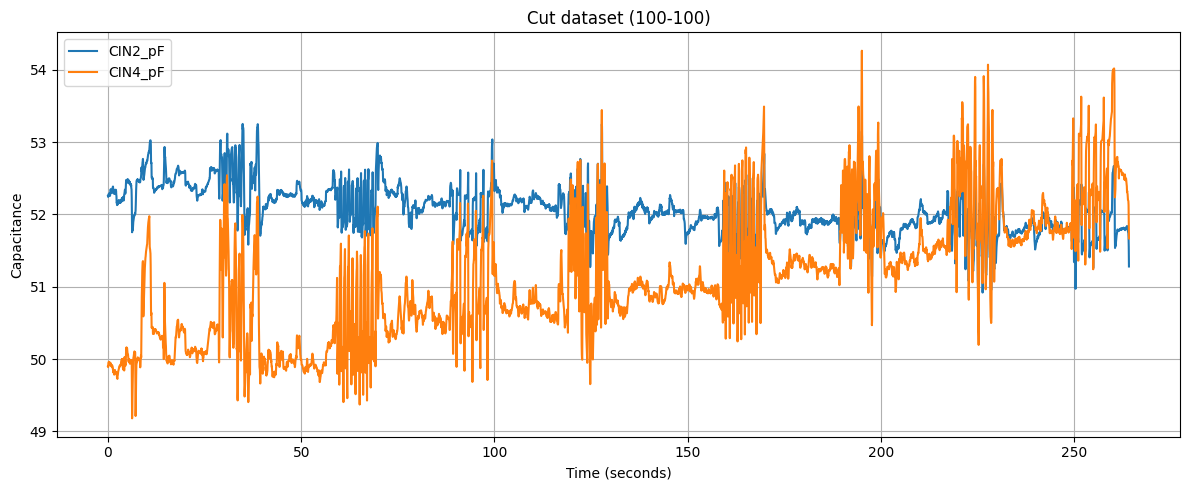

In [4]:
szeli_cut = cut_dataset(szeli_measurements, start=0, end=64)
plot(szeli_cut, channels="both", title="Cut dataset (100-100)")

(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'High-pass filtered CIN_2 and CIN_4'}, xlabel='Time (seconds)', ylabel='Capacitance'>)

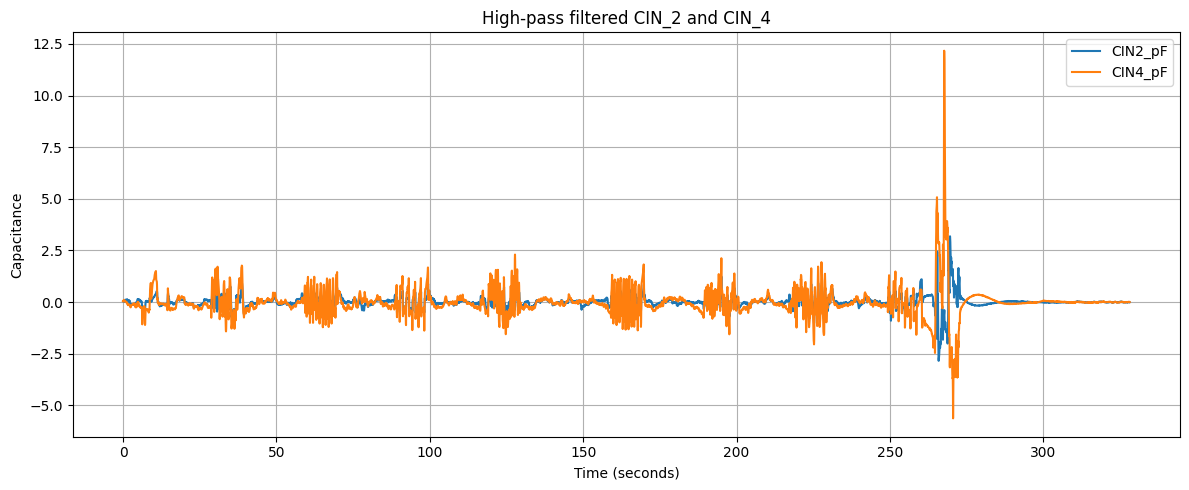

In [5]:
high_pass_filtered = highpass_transform(
    szeli_measurements,     #szeli_cut,
    cutoff_frequency=0.05,
    channels="both",
)

plot(high_pass_filtered, channels="both", title="High-pass filtered CIN_2 and CIN_4")

(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'RMS of high-pass filtered CIN_2 and CIN_4'}, xlabel='Time (seconds)', ylabel='Capacitance'>)

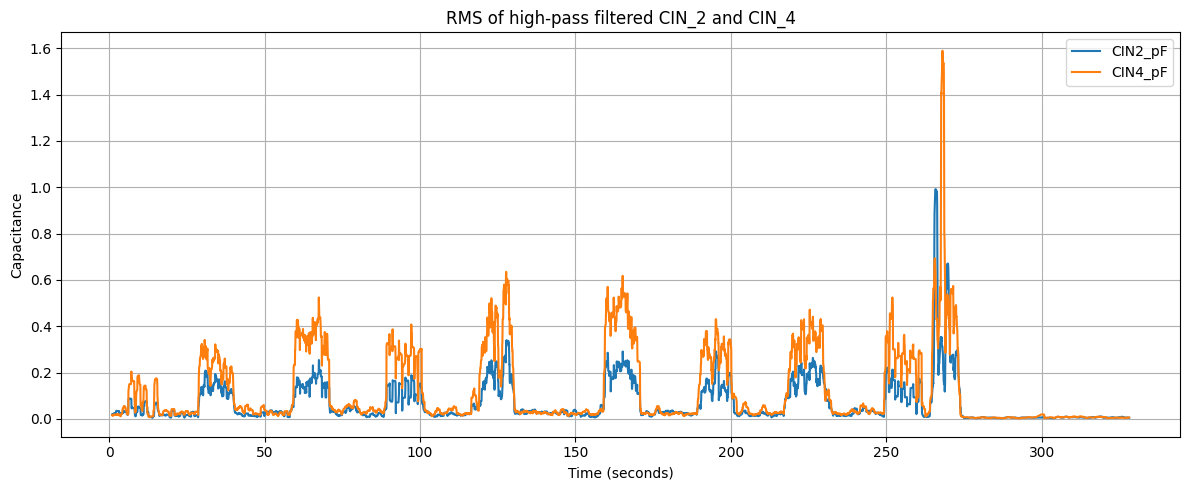

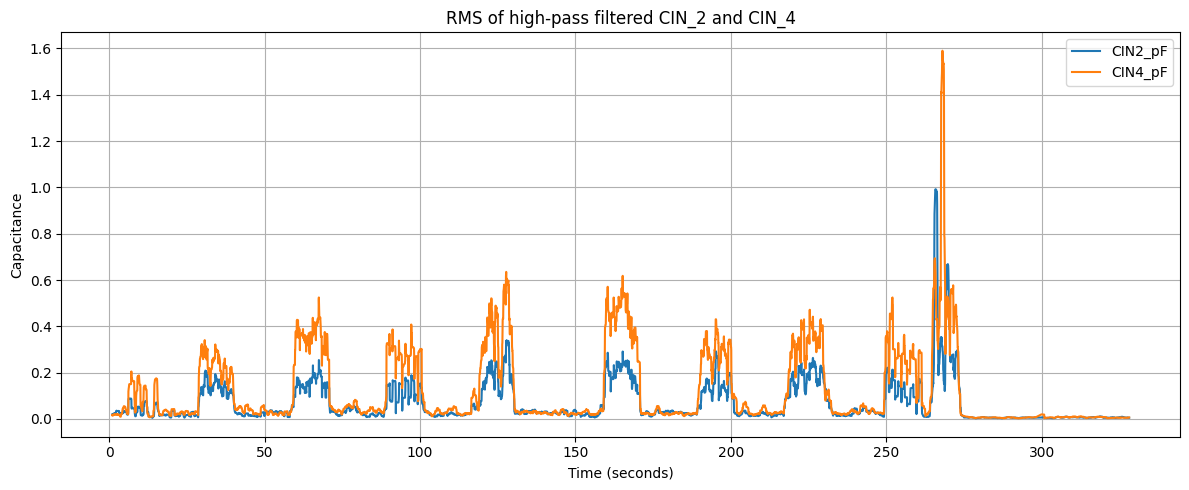

In [6]:
#20 Hz-es a mérés és 0.5 Hz egy lassú szemmozgás, akkor legalább 40 window_size kell 

szeli_rms = moving_rms(
    high_pass_filtered,
    window_size=20,
    channels="both",
)


plot(moving_rms(szeli_measurements,window_size=20, channels="both",), channels="both", title="RMS of high-pass filtered CIN_2 and CIN_4")
plot(szeli_rms, channels="both", title="RMS of high-pass filtered CIN_2 and CIN_4")

(<Figure size 1200x500 with 1 Axes>,
 <Axes: title={'center': 'Movement classification'}, xlabel='Time (seconds)', ylabel='Capacitance'>)

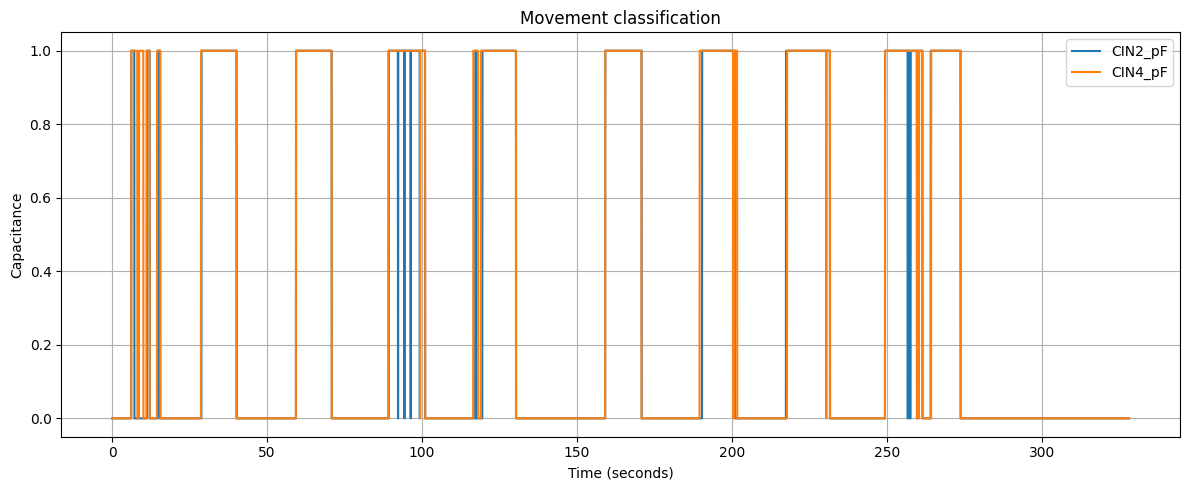

In [7]:
movement_left = threshold_transform(
    szeli_rms,
    threshold=0.065,
    channels="left",
)
movement_both = threshold_transform(
    movement_left,
    threshold=0.09,
    channels="right",
)

plot(movement_both, channels="both", title="Movement classification")

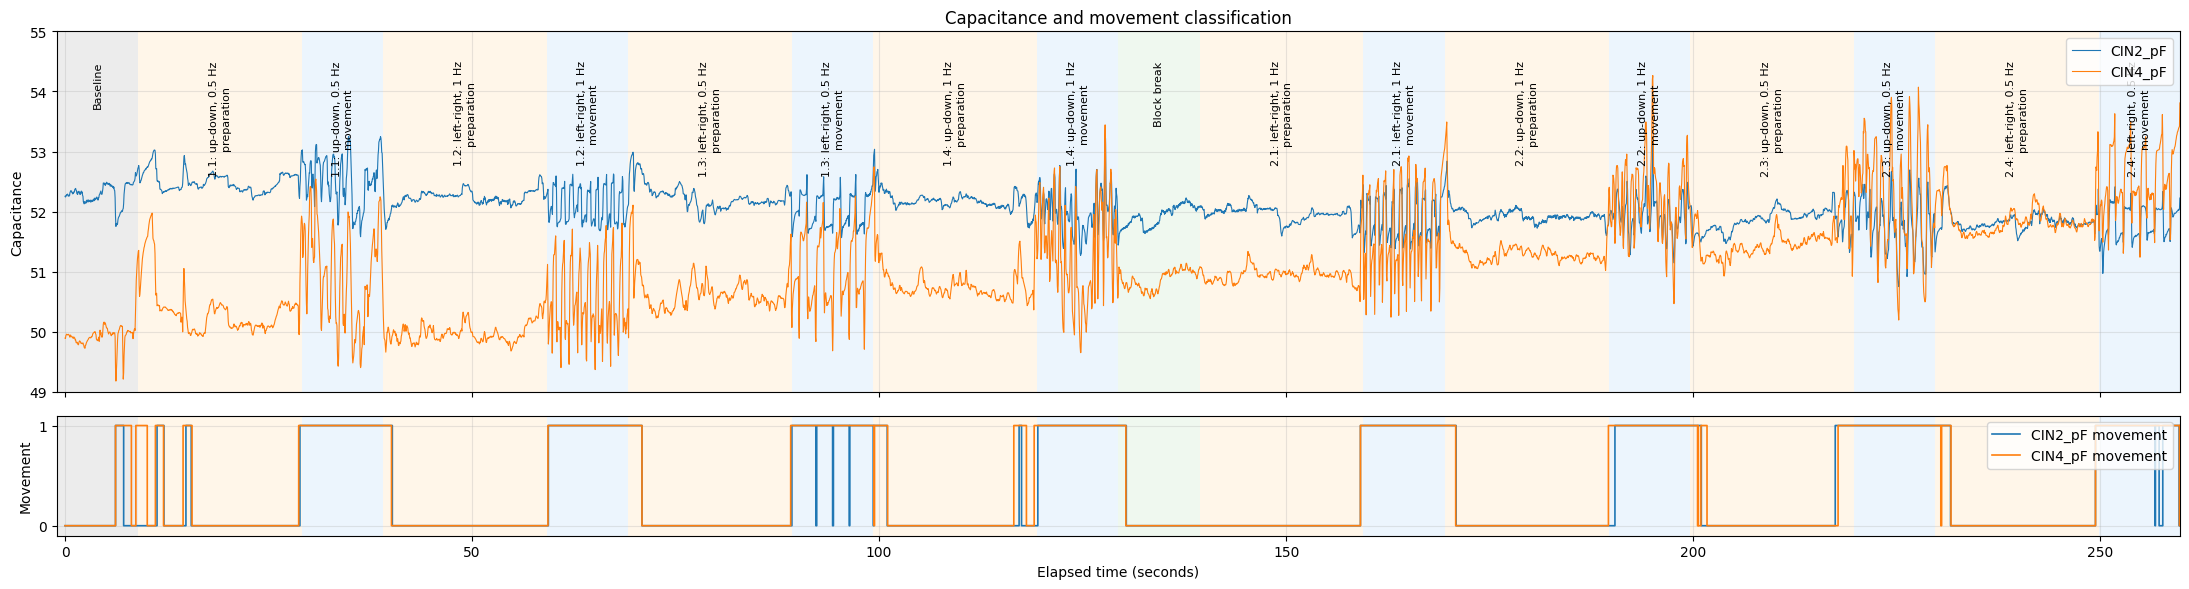

In [8]:
figure, axes, timeline = plot_capacity_classification(
    szeli_measurements,
    movement_both,
    [
        ("UD", 0.5, 10),
        ("LR", 1.0, 10),
        ("LR", 0.5, 10),
        ("UD", 1.0, 10),
    ],
    [
        ("LR", 1.0, 10),
        ("UD", 1.0, 10),
        ("UD", 0.5, 10),
        ("LR", 0.5, 10),
    ],
    baseline_seconds=10,
    rest_seconds=20,
    block_break_seconds=10,
    start_beep_seconds=0.1,
    ylim=(49, 55),
    offset_seconds=-1,
    end_padding_seconds=0,
    channels="both",
)